In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

In [2]:
import json

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

def save_json(file_name, file):
    with open(os.path.join(REPO_PATH, "data_files", f"{file_name}.json"), "w", encoding="utf-8") as out_file:
        json.dump(file, out_file, indent=4)

def load_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f]

# TODO:
1. Wikipedia harvest - Run as is for now, try to understand why it crushes near the end. **---------> DONE!**
2. Extract tables:
    - length between 3 to 10 **---------> DONE!**
    - table is square and parsed normally (no merged cells) **---------> DONE!**
    - full table **---------> DONE!**
    - remove some columns with no relevant data (empty or by keywords) **---------> DONE!**
3. Add to table extraction text titles and relevant paragraphs for the context. **---------> DONE!**
4. Cluster titles to remove similar options + take only one table per page. **---------> DONE!**
5. Create groups - all the table, try to see what is the main entity - return the column name, if they don't have one, discard the table and return 'None'. **---------> DONE!**
6. Create Questions
    - strategy injection, sample a subset of strategies in a shuffled order, if not possible than discard table.
    - make a function to extract the answer per question strategy --> create GT answer.
    - Add the 'group size' strategy.
    - constract the data samples.

### Havest Wikipedia pages with tables:

In [91]:
from knowledge_maze.create_dataset.create_questions.wikipedia_mining import WikiHarvester
# Initialize Wikipedia harvester
harvester = WikiHarvester()
# Run Phase 1 - Harvesting titles based on keywords
harvester.run_complete_harvest()
# Run Phase 2 - Filtering pages for tables
await harvester.filter_pages_async()

Harvesting Pages By Keywords:   0%|          | 0/233 [00:00<?, ?keyword/s]


TOTAL UNIQUE TITLES COLLECTED: 167913



Method,Keyword,Count
Prefix,List of cities,1537
Prefix,List of countries,1278
Prefix,List of towns,501
Prefix,List of villages,483
Prefix,List of districts,375
Prefix,List of municipalities,1021
Prefix,List of communes,194
Prefix,List of counties,259
Prefix,List of provinces,84
Prefix,List of territories,22


Filtering Pages with Tables:   0%|          | 0/167913 [00:00<?, ?page/s]


TOTAL PAGES WITH TABLES COLLECTED: 62306



In [93]:
save_json("table_titles", harvester.valid_titles)

In [3]:
table_titles = load_json("C:/Users/Daniel/Desktop/KnowledgeMaze/data_files/table_titles.json")

### Parse and filter Wikipedia tables:

In [4]:
from knowledge_maze.create_dataset.create_questions.table_processing import AsyncWikiExtractor

extractor = AsyncWikiExtractor(output_file=os.path.join(REPO_PATH, "data_files/final_tables.jsonl"))
validated_tables_file_name = await extractor.run_with_progress(table_titles)

Pre-processing: cluster similar pages and discard similarities ---> 6426 pages discarded.


Extracting Tables:   0%|          | 0/55880 [00:00<?, ?Page/s]

Starting Extraction: 55880 titles | Async Limit: 20 | CPU Workers: 19
TOTAL PAGES WITH VALID TABLES: 37946 OUT OF 55880 (67.9%)


In [5]:
validated_tables = load_jsonl(os.path.join(REPO_PATH, "data_files/final_tables.jsonl"))

In [70]:
from knowledge_maze.create_dataset.create_questions.table_processing import TablePostProcessor

processor = TablePostProcessor(os.path.join(REPO_PATH, "data_files/final_tables.jsonl"))
cleaned_data = processor.process()

Selecting Best Tables: 100%|█████████████████████████████████████████████████| 17442/17442 [00:00<00:00, 717648.13it/s]


════════════════════════════════════════════
📊 TABLE PROCESSING SUMMARY (Limit: 12)
════════════════════════════════════════════
Total tables scanned:      126924
Dropped (Single Col):      577
Dropped (Bad Headers):     9813
Dropped (Cell too long):   2682
Short tables found:        38679
Unique source pages:       17442
Final sampled (1/page):    17442
════════════════════════════════════════════

------------------------------------------------------------------------------------------------------------------------------------------------------
                                                                  ↓ EXAMPLE TABLES ↓                                                                  
------------------------------------------------------------------------------------------------------------------------------------------------------


═════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════

,Rank,Division,Gold,Silver,Bronze,Total
0,1,New England,4,5,1,10
1,2,Alaska,2,5,3,10
2,3,Intermountain,3,1,1,5
3,4,Pacific Northwest,2,0,2,4
4,5,Rocky Mountain,0,1,2,3
5,6,Far West*,0,0,1,1
6,7,Great Lakes,0,0,1,1
7,8,Midwest,0,0,1,1
8,9,High Plains,0,0,0,0
9,10,Mid-Atlantic,0,0,0,0



══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
List of phobias > Psychological conditions > G
══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════


,Phobia,Condition
0,Galeophobia,fear of sharks
1,Gamophobia,fear of marriage
2,Gelotophobia,fear of being laughed at
3,Gephyrophobia,fear of bridges
4,"Genophobia , coitophobia",fear of sexual intercourse
5,Genuphobia,fear of knees or the act of kneeling
6,Gerascophobia,fear of growing old or aging
7,Gerontophobia,"fear of growing old, or a hatred or fear of th..."
8,Globophobia,fear of balloons
9,Glossophobia,fear of speaking in public or of trying to speak



══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
List of members of the parliament of Malta, 2017–2022 > List by office
══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════


,Office,Officeholder,Year,Political party
0,President of Malta,Marie-Louise Coleiro Preca,2014–2019,Partit Laburista
1,President of Malta,George Vella,2019–present,Partit Laburista
2,Prime Minister of Malta,Joseph Muscat,2013–2020,Partit Laburista
3,Prime Minister of Malta,Robert Abela,2020–present,Partit Laburista
4,Leader of Opposition,Adrian Delia,2017–2020,Partit Nazzjonalista
5,Leader of Opposition,Bernard Grech,2020–present,Partit Nazzjonalista
6,Speaker,Anġlu Farrugia,2013–present,Partit Laburista



══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
List of adjectivals and demonyms of astronomical bodies > Moons (Saturn)
══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════


,Name,"Adjective, demonym"
0,Dione,Dionean
1,Enceladus,"Enceladean, Enceladan"
2,Hyperion,Hyperionian
3,Iapetus,"Iapetian, Japetian"
4,Mimas,"Mimantean, Mimantian"
5,Rhea,Rhean
6,Tethys,Tethyan
7,Titan,"Titanian / t aɪ ˈ t eɪ n i ə n / , Titanean"


### Create Potential Entity Groups:

In [175]:
from knowledge_maze.create_dataset.create_questions.grouping_entities import TableGroupConstructor

group_constructor = TableGroupConstructor(random.sample(cleaned_data, 1000))
await group_constructor.get_groups()

Creating groups based on the Wikipedia tables using LLM...


Usage cost: 0.3052$ (Estimated: 0.31$): 100%|██████████████████████████████████████| 1000/1000 [00:30<00:00, 33.28it/s]


════════════════════════════════════════════
📊 TABLE LLM GROUPING SUMMARY
════════════════════════════════════════════
Total tables scanned:      1000
Total groups made:      915
════════════════════════════════════════════

------------------------------------------------------------------------------------------------------------------------------------------------------
                                                                  ↓ EXAMPLE Groups ↓                                                                  
------------------------------------------------------------------------------------------------------------------------------------------------------


══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
--> Final WFTDA rankings of Central City Roller Derby from the 2013 to 2017 seasons.
--> Scheduled airlines operating in Sweden.
--> Individuals who have served as Ward

,Race and ethnicity,Total
0,Hispanic,72%
1,White,10%
2,Asian,6%
3,Black,5%
4,Two or more races,3%
5,Unknown,2%
6,Foreign national,1%
7,Economic diversity,Economic diversity
8,Low-income,59%
9,Affluent,41%



══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
--> Sex and the City > Episodes
══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════


,Season,Episodes,Originally released
0,First released,Last released,
1,1,12,12
2,2,18,18
3,3,18,18
4,4,18,18
5,5,8,8
6,6,20,12
7,6,20,8
8,Films,Films,Films


### Create FanOut Questions out of the Entity Groups:

In [179]:
from knowledge_maze.create_dataset.create_questions.question_generation import QuestionGenerator

question_generator = QuestionGenerator(random.sample(group_constructor.valid_tables, 50))
await question_generator.generate_questions()

Usage cost: 0.0090$ (Estimated: 0.01$): 100%|██████████████████████████████████████████| 50/50 [00:02<00:00, 18.80it/s]


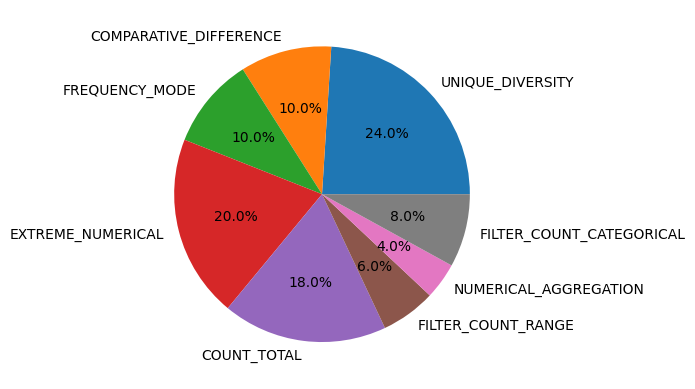

In [180]:
import matplotlib.pyplot as plt
from collections import Counter

def plot_categorical_pie(data):
    counts = Counter(data)
    plt.pie(counts.values(), labels=counts.keys(), autopct='%1.1f%%')

plot_categorical_pie([sample['Strategy'] for sample in question_generator.valid_tables])

In [181]:
for sample in question_generator.valid_tables:
    print(f"Group name: {sample['Group name']}")
    print(f"Strategy: {sample['Strategy']}")
    print(f"Question: {sample['Question']}")
    print(f"Entity column: {sample['Entity column']}")
    print(f"Data column: {sample['Data column']}")
    print(f"Wikipedia page: {sample['Wikipedia page']}")
    display(pd.DataFrame(sample['Table data']))
    print()
    print()

Group name: Faculties of the University of Arts in Belgrade, including Music Arts, Applied Arts, Dramatic Arts, Fine Arts, and Interdisciplinary Studies.
Strategy: UNIQUE_DIVERSITY
Question: How many different faculties are included in the University of Arts in Belgrade?
Entity column: Faculty
Data column: Faculty
Wikipedia page: https://en.wikipedia.org/wiki/University_of_Arts_in_Belgrade#Faculties


,Faculty,Location,Academic staff,Students
0,Music Arts,Belgrade,204,949
1,Applied Arts,Belgrade,104,820
2,Dramatic Arts,Belgrade,124,653
3,Fine Arts,Belgrade,57,352
4,Interdisciplinary Studies,Belgrade,-,131
5,Total,,489,2905




Group name: Racial and ethnic groups in St. Louis city, Missouri as of the 2020 census.
Strategy: COMPARATIVE_DIFFERENCE
Question: How many more people identified as Black or African American alone (NH) in 2010 compared to 2020 in St. Louis city, Missouri?
Entity column: Race / Ethnicity ( NH = Non-Hispanic )
Data column: Pop 2010
Wikipedia page: https://en.wikipedia.org/wiki/St._Louis#Demographics


,Race / Ethnicity ( NH = Non-Hispanic ),Pop 1980,Pop 1990,Pop 2000,Pop 2010,Pop 2020,% 1980,% 1990,% 2000,% 2010,% 2020
0,White alone (NH),239420,198956,149329,134702,129368,52.84%,50.15%,42.89%,42.19%,42.90%
1,Black or African American alone (NH),204970,187805,177446,156389,128993,45.24%,47.34%,50.96%,48.98%,42.77%
2,Native American or Alaska Native alone (NH),642,874,862,684,614,0.14%,0.22%,0.25%,0.21%,0.20%
3,Asian alone (NH),1696,3616,6820,9233,12205,0.37%,0.91%,1.96%,2.89%,4.05%
4,Native Hawaiian or Pacific Islander alone (NH),x,x,83,62,88,x,x,0.02%,0.02%,0.03%
5,Other race alone (NH),826,310,647,478,1773,0.18%,0.08%,0.19%,0.15%,0.59%
6,Mixed race or Multiracial (NH),x,x,5980,6616,13132,x,x,1.72%,2.07%,4.35%
7,Hispanic or Latino (any race),5531,5124,7022,11130,15405,1.22%,1.29%,2.02%,3.49%,5.11%
8,Total,453085,396685,348189,319294,301578,100.00%,100.00%,100.00%,100.00%,100.00%




Group name: Members of the TKO Board of Directors associated with WWE and Endeavor, including their roles and affiliations.
Strategy: UNIQUE_DIVERSITY
Question: How many different representatives are associated with the TKO Board of Directors?
Entity column: Name
Data column: Representative
Wikipedia page: https://en.wikipedia.org/wiki/List_of_WWE_personnel#Corporate_staff


...

,State,Also claimed by,Head of state,Head of government
0,Abkhazia,Georgia,President – Badra Gunba,President – Badra Gunba
1,Republic of China (Taiwan),People's Republic of China,President – Lai Ching-te,Premier – Cho Jung-tai
2,Kosovo,Serbia,President – Vjosa Osmani,Acting Prime Minister – Albin Kurti
3,Northern Cyprus,Cyprus,President – Tufan Erhürman,Prime Minister – Ünal Üstel
4,Sahrawi Republic,Morocco,General Secretary of the Polisario Front – Bra...,General Secretary of the Polisario Front – Bra...
5,Sahrawi Republic,Morocco,President – Brahim Ghali,Prime Minister – Bouchraya Hammoudi Bayoun
6,Somaliland,Somalia,President – Abdirahman Mohamed Abdullahi,President – Abdirahman Mohamed Abdullahi
7,South Ossetia,Georgia,President – Alan Gagloyev,Prime Minister – Konstantin Dzhussoyev




Group name: Riders from Team Halfords Bikehut who participated in major women's cycling races.
Strategy: FILTER_COUNT_CATEGORICAL
Question: How many riders participated in the European Track Championships?
Entity column: Rider
Data column: Race
Wikipedia page: https://en.wikipedia.org/wiki/Team_Halfords_Bikehut#Results_in_major_races


,Date,Race,Rider,Place
0,28 March,Track Cycling World Championships – Women's te...,Joanna Rowsell Wendy Houvenaghel (with Rebecca...,
1,29 March,Track Cycling World Championships – Women's po...,Lizzie Armitstead,19th
2,30 March,Track Cycling World Championships – Women's sc...,Lizzie Armitstead,7th
3,10 August,Summer Olympics – Women's road race,Nicole Cooke ( GBR ),
4,3 September,European Track Championships – Women's omnium,Ellen van Dijk,
5,September,European Track Championships – Women's under-2...,Lizzie Armitstead Katie Colclough Joanna Rowsell,
6,6 September,European Track Championships – Women's under-2...,Joanna Rowsell,
7,7 September,European Track Championships – Women's under-2...,Lizzie Armitstead Ex aequo with Ellen van Dijk,
8,6 September,European Track Championships – Women's under-2...,Lizzie Armitstead,
9,24 September,Road World Championships – Women's road race,Nicole Cooke ( GBR ),




Group name: The 10 largest employers in the world ranked by the number of employees, including government and private organizations.
Strategy: UNIQUE_DIVERSITY
Question: How many different countries are represented by the 10 largest employers in the world?
Entity column: Employer
Data column: Country
Wikipedia page: https://en.wikipedia.org/wiki/List_of_largest_employers#Largest_employers


,Rank,Employer,Employees (mn),Country
0,1,Ministry of Defence (India),9.26,India
1,2,United States Department of Defense,2.91,United States
2,3,People's Liberation Army,3.15,China
3,4,Walmart,2.30,United States
4,5,Amazon,1.61,United States
5,6,China National Petroleum,1.45,China
6,7,National Health Service,1.38,United Kingdom
7,8,Foxconn,1.29,Taiwan
8,9,Indian Railways,1.21,India
9,10,Tata Group,1.15,India


In [124]:
def filter_tables_by_noise(tables):
    """
    Filters a list of tables to find those containing 'total' in values
    or rows with identical values across all columns.
    """
    suspicious_tables = []

    for table in tables:
        rows = table.get('Table data', [])
        found_noise = False
        
        for row in rows:
            values = list(row.values())
            
            # 1. Check for 'total' in any value (case-insensitive)
            if any("total" in str(v).lower() for v in values):
                found_noise = True
                break
            
            # 2. Check if all values in the row are exactly the same
            # (Ensuring row has more than 1 column to avoid false positives)
            if len(values) > 1 and len(set(values)) == 1:
                found_noise = True
                break
        
        if found_noise:
            suspicious_tables.append(table)
            
    return suspicious_tables

In [125]:
sus_tables = filter_tables_by_noise(group_constructor.valid_tables)
print(len(sus_tables))

153


In [121]:
for sus in sus_tables:
    print(f"Group name: {sus['Group name']}")
    print(f"Entity column: {sus['Entity column']}")
    display(pd.DataFrame(sus['Table data']))

Group name: Live albums released by Bob Marley and the Wailers.
Entity column: Title


,Title,Album details,Peak chart positions,Certifications ( sales thresholds )
0,AUS,NZ,SWE,SWI
1,Live!,Released: 5 December 1975 Labels: Island / Tuf...,51,—
2,Babylon by Bus,Released: 10 November 1978 Labels: Island/Tuff...,34,21
3,Talkin' Blues,Released: 4 February 1991 Labels: Island/Tuff ...,—,30
4,Live at the Roxy,Released: 24 June 2003 Labels: Island/Tuff Gon...,—,—
5,"Live Forever: September 23, 1980 • Stanley The...",Released: 2011 Labels: Island/Tuff Gong Format:,—,—
6,Easy Skanking in Boston '78,Released: 2015 Labels: Island/Tuff Gong Format:,—,—
7,"Live at the Rainbow, 1st June 1977",Released: 12 June 2020 Labels: Tuff Gong Forma...,—,—
8,"Live at the Rainbow, 2nd June 1977",Released: 12 June 2020 Labels: Tuff Gong Forma...,—,—
9,"Live at the Rainbow, 3rd June 1977",Released: 12 June 2020 Labels: Tuff Gong Forma...,—,—


Group name: Tournament performance records of the Sápmi football team in the VIVA World Cup and ConIFA World Football Cup.
Entity column: Year


,Year,Position,GP,W,D,L,GS,GA
0,VIVA World Cup,VIVA World Cup,VIVA World Cup,VIVA World Cup,VIVA World Cup,VIVA World Cup,VIVA World Cup,VIVA World Cup
1,2006,Champion,3,3,0,0,41,1
2,2008,Third place,5,2,1,2,9,8
3,2009,Third place,4,1,1,2,12,12
4,2010,did not enter,did not enter,did not enter,did not enter,did not enter,did not enter,did not enter
5,2012,did not enter,,,,,,
6,ConIFA World Football Cup,ConIFA World Football Cup,ConIFA World Football Cup,ConIFA World Football Cup,ConIFA World Football Cup,ConIFA World Football Cup,ConIFA World Football Cup,ConIFA World Football Cup
7,2014,Group stage,4,1,0,3,6,10
8,2016,Quarter-finals,5,3,0,2,10,4
9,2018,did not qualify,did not qualify,did not qualify,did not qualify,did not qualify,did not qualify,did not qualify


Group name: International athletic competitions participated in by Alejandro Herrera, focusing on his performances in the triple jump and long jump events.
Entity column: Competition


...

,Race and ethnicity,Total
0,White,48%
1,Black,27%
2,Asian,9%
3,Hispanic,8%
4,Two or more races,5%
5,International student,2%
6,Unknown,1%
7,Economic diversity,Economic diversity
8,Low-income,34%
9,Affluent,66%


Group name: International athletic competitions in which Krzysztof Krawczyk represented Poland and his positions in those events.
Entity column: Competition


,Year,Competition,Venue,Position,Notes
0,Representing Poland,Representing Poland,Representing Poland,Representing Poland,Representing Poland
1,1981,European Indoor Championships,"Grenoble, France",6th,2.19 m
2,1981,European Junior Championships,"Utrecht, Netherlands",1st,2.26 m
3,1984,European Indoor Championships,"Gothenburg, Sweden",12th,2.15 m
4,1985,World Indoor Games,"Paris, France",7th,2.21 m
5,1986,European Indoor Championships,"Madrid, Spain",6th,2.24 m
6,1986,European Championships,"Stuttgart, West Germany",5th,2.28 m
7,1987,European Indoor Championships,"Liévin, France",8th,2.24 m
8,1987,Universiade,"Zagreb, Yugoslavia",6th,2.24 m
9,1987,World Championships,"Rome, Italy",12th,2.24 m


Group name: Opponents faced by the Australia women's national cricket team in Twenty20 Internationals along with match results.
Entity column: Opponent


,Opponent,Mat,Won,Lost,Tied,NR,First match,First win
0,ICC Full members,ICC Full members,ICC Full members,ICC Full members,ICC Full members,ICC Full members,ICC Full members,ICC Full members
1,Bangladesh,5,5,0,0,0,27 February 2020,27 February 2020
2,Barbados,1,1,0,0,0,31 July 2022,31 July 2022
3,England,45,23,21,0,1,2 September 2005,2 September 2005
4,India,35,26,8,0,1,28 October 2008,28 October 2008
5,Ireland,8,8,0,0,0,27 March 2014,27 March 2014
6,New Zealand,55,33,21,0,1,18 October 2006,19 July 2007
7,Pakistan,16,14,0,0,2,29 September 2012,29 September 2012
8,South Africa,11,9,2,0,0,7 May 2010,7 May 2010
9,Sri Lanka,8,8,0,0,0,27 September 2016,27 September 2016


In [122]:
def test_noise_distribution(tables):
    stats = {"total_found": 0, "duplicates_found": 0, "both": 0}
    
    for table in tables:
        rows = table.get('Table data', []) or table.get('rows', [])
        has_total = False
        has_dup = False
        
        for row in rows:
            values = list(row.values())
            if not values: continue
            
            # Check 1: "Total" presence
            if any("total" in str(v).lower() for v in values):
                has_total = True
            
            # Check 2: Row redundancy (all values identical)
            if len(values) > 1 and len(set(values)) == 1:
                has_dup = True
        
        # Tallying the results
        if has_total and has_dup:
            stats["both"] += 1
        elif has_total:
            stats["total_found"] += 1
        elif has_dup:
            stats["duplicates_found"] += 1

    # Printing the summary
    width = 40
    print("\n" + "═" * width)
    print("🧹 NOISE DETECTION SUMMARY")
    print("═" * width)
    print(f"Tables with 'Total':      {stats['total_found']}")
    print(f"Tables with Duplicates:   {stats['duplicates_found']}")
    print(f"Tables with BOTH:         {stats['both']}")
    print("─" * width)
    print(f"Total Noisy Tables:       {sum(stats.values())}")
    print("═" * width + "\n")

    return stats

In [123]:
test_noise_distribution(group_constructor.valid_tables)


════════════════════════════════════════
🧹 NOISE DETECTION SUMMARY
════════════════════════════════════════
Tables with 'Total':      85
Tables with Duplicates:   64
Tables with BOTH:         4
────────────────────────────────────────
Total Noisy Tables:       153
════════════════════════════════════════



{'total_found': 85, 'duplicates_found': 64, 'both': 4}